Note: data/SMA warm-up limits the start to 2001-06-18


,SMA Strategy,Buy & Hold Risk-On,Buy & Hold SPY
CAGR,27.10%,20.67%,9.48%
Sortino,1.23,0.89,0.81
Ulcer Index,16.42,38.48,12.92
Max Drawdown,-43.45%,-87.68%,-55.19%
Avg Drawdown,-6.08%,-6.50%,-1.84%
Max DD Length (days),467,1577,1224
Avg DD Length (days),22.7,30.6,18.3
Final Growth of $1,433.95,116.73,9.91
Switches,17,-,-
% Time Risk-On,74.7%,-,-


,Switch Date,From,To,Price,SMA 200,Reason,Effective Date
0,2003-04-22,Risk-Off,Risk-On,59.596840,57.207744,Reclaimed SMA 200 × (1 + 4.0%) (lowest breache...,2003-04-23
1,2007-11-26,Risk-On,Risk-Off,99.617462,104.291649,Broke below SMA 200 × (1 - 4.0%),2007-11-27
2,2009-06-09,Risk-Off,Risk-On,69.353867,66.655574,Reclaimed SMA 200 × (1 + 4.0%) (lowest breache...,2009-06-10
3,2010-06-07,Risk-On,Risk-Off,78.855858,82.439783,Broke below SMA 200 × (1 - 4.0%),2010-06-08
4,2010-10-05,Risk-Off,Risk-On,87.621475,83.834198,Reclaimed SMA 200 × (1 + 4.0%) (lowest breache...,2010-10-06
5,2011-08-04,Risk-On,Risk-Off,92.136650,97.960057,Broke below SMA 200 × (1 - 4.0%),2011-08-05
6,2012-01-18,Risk-Off,Risk-On,101.345871,96.623232,Reclaimed SMA 200 × (1 + 4.0%) (lowest breache...,2012-01-19
7,2015-08-21,Risk-On,Risk-Off,164.529419,171.727730,Broke below SMA 200 × (1 - 4.0%),2015-08-24
8,2016-04-13,Risk-Off,Risk-On,175.823929,168.623429,Reclaimed SMA 200 × (1 + 4.0%) (lowest breache...,2016-04-14
9,2018-12-14,Risk-On,Risk-Off,231.084534,243.368472,Broke below SMA 200 × (1 - 4.0%),2018-12-17


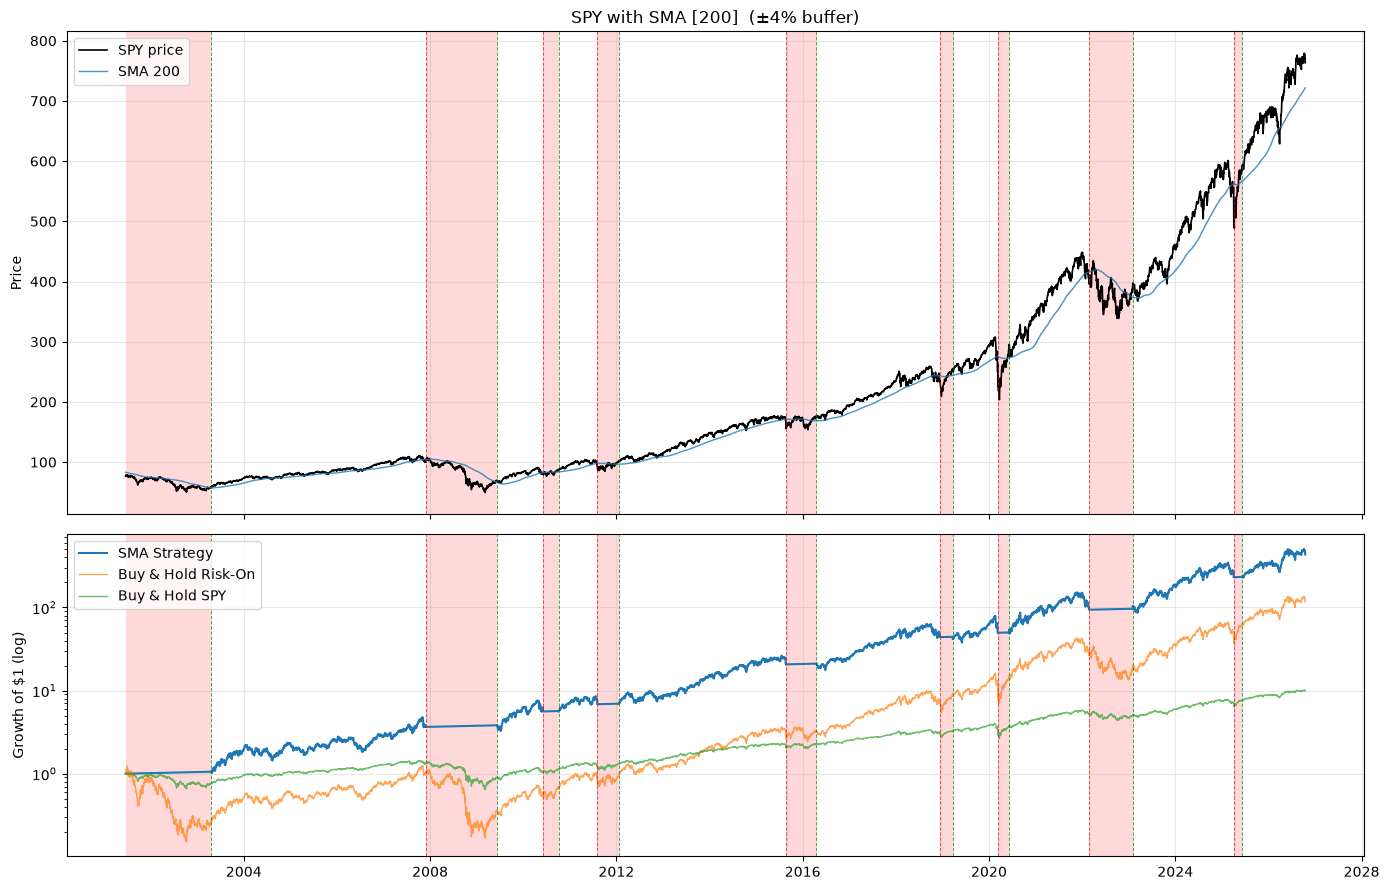

In [33]:
# ==============================================================
# SMA Risk-On / Risk-Off Backtester  (single Jupyter cell)
# pip install yfinance pandas numpy matplotlib
# ==============================================================
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------- INPUTS -------------------------------
RISK_ON  = {"^NDX": 0.75*3, "GC=F": 0.25*0.5}   # "^NDX": 1.5, '^SPX':1.5 vs "^NDX": 3
RISK_OFF = {"QQQ": -1}   # same format; ignored if USE_CASH_WHEN_OFF = True
USE_CASH_WHEN_OFF = True             # True -> risk-off goes to cash growing at CASH_RATE
CASH_RATE = 0.03                      # annualized cash return
SMA_LIST = [200]             # risk-off on the FIRST of these breached below (with buffer)
LOWER_BUFFER = 0.04               # exit below SMA*(1-LOWER_BUFFER)
UPPER_BUFFER = 0.04               # re-enter above SMA*(1+UPPER_BUFFER) of the lowest SMA breached this episode
SIGNAL_TICKER = "SPY"                 # price the SMAs are computed on (and plotted)
START = "1999-03-10"
END   = "2026-10-17"
BORROW_RATE = 0.0                     # optional annual cost on gross exposure (sum of |w|) above 100% (0 = ignore)
TRADING_DAYS = 252
REBALANCE_EVERY = 21*3
# ----------------------------------------------------------------


def download_prices(tickers, start, end):
    data = yf.download(sorted(set(tickers)), start=start, end=end,
                       auto_adjust=True, progress=False)
    close = data["Close"] if isinstance(data.columns, pd.MultiIndex) or "Close" in data else data
    if isinstance(close, pd.Series):
        close = close.to_frame(tickers[0])
    return close.dropna(how="any")


def portfolio_returns(weights, rets, rebalance_every=1, daily_reset=True):
    target = pd.Series(weights, dtype=float).reindex(rets.columns).fillna(0.0)
    if daily_reset:
        # each sleeve is a daily-reset leveraged ETF; weights are the MIX between sleeves
        lev = target.abs().sum()
        mix = (target / lev) if lev else target
        sleeve_rets = rets.mul(np.sign(target) * lev, axis=1)  # per-ticker daily-reset lev return
        current = mix.copy(); out = []
        for i, (_, dr) in enumerate(sleeve_rets.iterrows()):
            if i % rebalance_every == 0:
                current = mix.copy()
            dr = dr.fillna(0.0)
            pr = float((current * dr).sum())
            pr -= max(lev - 1.0, 0.0) * BORROW_RATE / TRADING_DAYS
            pr = max(pr, -1.0); out.append(pr)
            if pr > -1.0:
                current = current * (1.0 + dr) / (1.0 + pr)
        return pd.Series(out, index=rets.index)


def compute_signal(px, sma_list, lower_buffer, upper_buffer):
    """
    True = risk on.
    Exit:     the first SMA price closes below SMA*(1-lower) -> risk off.
    While off, remember every SMA that was actually breached (below SMA*(1-lower)) during the episode.
    Re-enter: price closes above SMA*(1+upper) of the LOWEST (by current value) breached SMA.
              SMAs never breached this episode are ignored, e.g. break the 150 but never the 200
              -> re-enter on reclaiming the 150 even if still below the 200.
    """
    smas = pd.concat({n: px.rolling(n).mean() for n in sma_list}, axis=1)
    valid = smas.notna().all(axis=1)
    p, s = px.values, smas.values
    below = p[:, None] < s * (1 - lower_buffer)     # per-SMA breach, shape (bars, n_smas)
    above = p[:, None] > s * (1 + upper_buffer)
    names = np.array(sma_list)

    state = np.full(len(px), np.nan)
    reason = pd.Series("", index=px.index, dtype=object)
    cur, breached = None, np.zeros(len(sma_list), dtype=bool)
    for i in range(len(px)):
        if not valid.iloc[i]:
            continue
        if cur is None:                                   # first bar: no buffer, just above/below
            cur = bool((p[i] > s[i]).all())
            breached = p[i] <= s[i]
        elif cur:
            if below[i].any():
                cur = False
                breached = below[i].copy()
                reason.iloc[i] = (f"Broke below SMA {', '.join(map(str, names[breached]))} "
                                  f"× (1 - {lower_buffer:.1%})")
        else:
            breached |= below[i]                          # deeper breaches during the episode
            j = np.flatnonzero(breached)
            k = j[np.argmin(s[i, j])]                     # lowest breached SMA today
            if above[i, k]:
                cur = True
                reason.iloc[i] = (f"Reclaimed SMA {names[k]} × (1 + {upper_buffer:.1%}) "
                                  f"(lowest breached of {', '.join(map(str, names[j]))})")
                breached[:] = False
        state[i] = cur
    return pd.Series(state, index=px.index), smas, reason


def drawdown_episodes(eq):
    dd = eq / eq.cummax() - 1
    eps, start = [], None
    for i, d in enumerate(dd.values):
        if d < 0 and start is None:
            start = i
        elif d == 0 and start is not None:
            eps.append((dd.iloc[start:i].min(), i - start + 1))   # depth, length incl. recovery day
            start = None
    if start is not None:                                          # unrecovered at end
        eps.append((dd.iloc[start:].min(), len(dd) - start))
    return dd, eps


def summarize(rets, name):
    eq = (1 + rets).cumprod()
    years = (eq.index[-1] - eq.index[0]).days / 365.25
    cagr = eq.iloc[-1] ** (1 / years) - 1 if eq.iloc[-1] > 0 else -1.0
    downside = np.sqrt((np.minimum(rets, 0) ** 2).mean()) * np.sqrt(TRADING_DAYS)
    sortino = rets.mean() * TRADING_DAYS / downside if downside > 0 else np.nan
    dd, eps = drawdown_episodes(eq)
    ulcer = np.sqrt(((dd * 100) ** 2).mean())
    depths = [e[0] for e in eps] or [0.0]
    lengths = [e[1] for e in eps] or [0]
    return pd.Series({
        "CAGR": f"{cagr:.2%}",
        "Sortino": f"{sortino:.2f}",
        "Ulcer Index": f"{ulcer:.2f}",
        "Max Drawdown": f"{min(depths):.2%}",
        "Avg Drawdown": f"{np.mean(depths):.2%}",
        "Max DD Length (days)": int(max(lengths)),
        "Avg DD Length (days)": f"{np.mean(lengths):.1f}",
        "Final Growth of $1": f"{eq.iloc[-1]:.2f}",
    }, name=name), eq


# ------------------------- RUN ----------------------------------
off_tickers = [] if USE_CASH_WHEN_OFF else list(RISK_OFF)
tickers = list(RISK_ON) + off_tickers + [SIGNAL_TICKER]
warmup_start = pd.Timestamp(START) - pd.Timedelta(days=int(max(SMA_LIST) * 1.6) + 30)
prices = download_prices(tickers, warmup_start, END)
rets = prices.pct_change()

signal, smas, reasons = compute_signal(prices[SIGNAL_TICKER], SMA_LIST, LOWER_BUFFER, UPPER_BUFFER)

# Trim to backtest window (need SMAs ready)
mask = (prices.index >= pd.Timestamp(START)) & signal.notna()
idx = prices.index[mask]
if idx[0] > pd.Timestamp(START) + pd.Timedelta(days=7):
    print(f"Note: data/SMA warm-up limits the start to {idx[0].date()}")
signal = signal.loc[idx].astype(bool)
rets = rets.loc[idx].fillna(0)

on_ret = portfolio_returns(RISK_ON, rets, rebalance_every=REBALANCE_EVERY)
if USE_CASH_WHEN_OFF:
    off_ret = pd.Series((1 + CASH_RATE) ** (1 / TRADING_DAYS) - 1, index=idx)
else:
    off_ret = portfolio_returns(RISK_OFF, rets, rebalance_every=REBALANCE_EVERY)

# Trade on the close the signal fires -> new allocation earns the NEXT day's return (no look-ahead)
position = signal.shift(1).fillna(signal.iloc[0]).astype(bool)
strat_ret = pd.Series(np.where(position, on_ret, off_ret), index=idx)
strat_ret.iloc[0] = 0.0
on_ret.iloc[0] = 0.0
bh_sig = rets[SIGNAL_TICKER].copy(); bh_sig.iloc[0] = 0.0

s1, eq_strat = summarize(strat_ret, "SMA Strategy")
s2, eq_on    = summarize(on_ret, "Buy & Hold Risk-On")
s3, eq_sig   = summarize(bh_sig, f"Buy & Hold {SIGNAL_TICKER}")
summary = pd.concat([s1, s2, s3], axis=1)
summary.loc["Switches"] = [int((signal != signal.shift()).sum() - 1), "-", "-"]
summary.loc["% Time Risk-On"] = [f"{position.mean():.1%}", "-", "-"]
display(summary)

# ------------------------- PLOT ---------------------------------
# ------------------------- SWITCH TABLE -------------------------
previous_signal = signal.shift()
switch_mask = signal.ne(previous_signal) & previous_signal.notna()
switch_dates = signal.index[switch_mask]

switch_table = pd.DataFrame({
    "Switch Date": switch_dates,
    "From": previous_signal.loc[switch_dates].map({True: "Risk-On", False: "Risk-Off"}).to_numpy(),
    "To": signal.loc[switch_dates].map({True: "Risk-On", False: "Risk-Off"}).to_numpy(),
    "Price": prices[SIGNAL_TICKER].loc[switch_dates].to_numpy(),
})

for n in SMA_LIST:
    switch_table[f"SMA {n}"] = smas[n].loc[switch_dates].to_numpy()

switch_table["Reason"] = reasons.loc[switch_dates].to_numpy()

# The allocation changes on the close and earns returns starting the next day.
next_dates = pd.Series(idx, index=idx).shift(-1).reindex(switch_dates)
switch_table["Effective Date"] = next_dates.dt.strftime("%Y-%m-%d").fillna("End of test").to_numpy()

display(switch_table.reset_index(drop=True))

# risk-off spans: from exit date to re-entry date (or end)
spans, off_start = [], (idx[0] if not signal.iloc[0] else None)
for d in switch_dates:
    if not signal.loc[d]:
        off_start = d
    elif off_start is not None:
        spans.append((off_start, d)); off_start = None
if off_start is not None:
    spans.append((off_start, idx[-1]))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True,
                               gridspec_kw={"height_ratios": [3, 2]})
px = prices[SIGNAL_TICKER].loc[idx]
ax1.plot(px.index, px, color="black", lw=1.2, label=f"{SIGNAL_TICKER} price")
for n in SMA_LIST:
    ax1.plot(idx, smas[n].loc[idx], lw=1, alpha=0.8, label=f"SMA {n}")
ax1.set_title(f"{SIGNAL_TICKER} with SMA {SMA_LIST}  (-{LOWER_BUFFER:.0%} / +{UPPER_BUFFER:.0%} buffer)")
ax1.set_ylabel("Price")

ax2.plot(eq_strat.index, eq_strat, lw=1.5, label="SMA Strategy")
ax2.plot(eq_on.index, eq_on, lw=1, alpha=0.7, label="Buy & Hold Risk-On")
ax2.plot(eq_sig.index, eq_sig, lw=1, alpha=0.7, label=f"Buy & Hold {SIGNAL_TICKER}")
ax2.set_yscale("log")
ax2.set_ylabel("Growth of $1 (log)")

for ax in (ax1, ax2):
    for a, b in spans:
        ax.axvspan(a, b, color="red", alpha=0.15, lw=0)
    for d in switch_dates:
        ax.axvline(d, color="red" if not signal.loc[d] else "green", ls="--", lw=0.7, alpha=0.7)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()